In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from typing import Optional, Tuple
from dualwcfm import (
    Strategy,
    BidirectionalStrategy,
    Trainer,
    ImplicitCFMLoss,
    ConditionalFlowMatching,
    TrainingConfig,
    FeedForwardConfig,
    Visualizer,
    Visualizer3D,
    VisualizerImage,
    VisualizeConfig,
)
from dualwcfm.distributions import (
    CouplingDistribution,
    RotatedShapeCoupling,
    Simple2DGaussianDistribution,
    RotatedDistribution,
    MoonDistribution,
    SphereDistribution,
    MarginalDistribution
)
from dualwcfm.models.unet import UNetModel
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class unet_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, t, x=None, inp3=None, *args, **kwargs):
        if inp3 is not None and x is not None:
            return self.model(t, torch.cat([x, inp3], dim=1))
        if x is not None:
            return self.model(t, x)
        else:
            return self.model(t, torch.zeros_like(t))

class torch_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
        if inp3 is not None and inp2 is not None:
            return self.model(torch.cat([inp2, inp3, inp1], dim=1))
        if inp2 is not None:
            return self.model(torch.cat([inp2, inp1], dim=1))
        else:
            return self.model(inp1)

c:\Users\Antoine\AppData\Local\Programs\Python\Python39\lib\site-packages\cupy\_environment.py:216: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [3]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import numpy as np

class ImageSampler:
    """Helper to turn a DataLoader into an infinite sampler."""

    def __init__(self, dataset, batch_size, device):
        self.loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=True)
        self.iterator = iter(self.loader)
        self.device = device

    def get_batch(self, n):
        try:
            batch, _ = next(self.iterator)
        except StopIteration:
            self.iterator = iter(self.loader)
            batch, _ = next(self.iterator)
        return batch[:n].to(self.device)

class FlipCoupling(CouplingDistribution):

    def __init__(self, dataset, batch_size=32, device: Optional[torch.device] = None):
        self.device = device if device is not None else torch.device("cpu")
        self.sampler = ImageSampler(dataset, batch_size, self.device)

    def coupling_sample(self, n: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.sampler.get_batch(n)
        y = torch.flip(x, dims=[2])
        return x, y

    def sample(self, n: int) -> torch.Tensor:
        raise NotImplementedError

    def sample_init(self, n: int) -> torch.Tensor:
        return self.sampler.get_batch(n)

    def sample_target(self, n: int) -> torch.Tensor:
        return torch.flip(self.sampler.get_batch(n), dims=[2])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_image = False

if use_image:
    batch_size = 128
    tf = T.Compose([T.Resize(32), T.ToTensor(), T.Normalize((0.5,), (0.5,))])

    ds_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)
    ds_fashion = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tf)

    print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    subset_size = 10000

    # 3. Create random indices and wrap in a Subset
    mnist_indices = np.random.choice(len(ds_mnist), subset_size, replace=False)
    fashion_indices = np.random.choice(len(ds_fashion), subset_size, replace=False)

    ds_mnist = Subset(ds_mnist, mnist_indices)
    ds_fashion = Subset(ds_fashion, fashion_indices)
    
    print(f"MNIST size: {len(ds_mnist)}, FashionMNIST size: {len(ds_fashion)}")

    coupling = FlipCoupling(dataset=ds_fashion, batch_size=batch_size, device=device)

    new_coupling_dist = FlipCoupling(dataset=ds_mnist, batch_size=batch_size, device=device)
    new_source = MarginalDistribution(new_coupling_dist.sample_init)
    new_target = MarginalDistribution(new_coupling_dist.sample_target)

else:
    batch_size = 4096
    def anticorrelate(n: int):
        source_samples = torch.randn(n, 2) * 0.5
        return source_samples, -source_samples

    coupling = FunctionalCouplingDistribution(anticorrelate)
    source, target = coupling.get_marginals()
    new_source = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([1.0, 1.0]))
    new_target = Simple2DGaussianDistribution(mean=torch.tensor([-5.0, -5.0]), std=torch.tensor([1.0, 1.0]))

In [4]:
class BidirectionalUnetStrategy(BidirectionalStrategy):
    # UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True).to(device)
    def _create_models(self, dim: int, hidden_size: int):
        wrapper = self.wrapper
        self.mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.f_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))
        self.g_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))

        self.forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

        self.initial_mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

In [8]:
training_config = TrainingConfig(
    device=device,
    iterations=50,
    dataset_size=100000,
    marginal_epochs=5000,
    sigma=0.1,
    batch_size=batch_size,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size
)
small_training_config = TrainingConfig(
    device=device, iterations=200, batch_size=batch_size,
    dataset_size=1000,
    marginal_epochs=50, pretrain_epochs=50, dual_epochs=5, cfm_epochs=5,
    use_disk_coupling=True,
    coupling_save_dir='experiments/coupling_data',
    coupling_chunk_size=batch_size,
)
model_config = FeedForwardConfig(dimension=2, hidden_size=32, dual_learning_rate=1e-4, flow_learning_rate=1e-3, mu_learning_rate=1e-3, nu_learning_rate=1e-3)

flow_matching = ConditionalFlowMatching()
viz_config = VisualizeConfig(show_each=10, show_each_marginal=1000, show_each_pretrain=1000)
if use_image:
    strategy = BidirectionalUnetStrategy(unet_wrapper, model_config)
    visualizer = VisualizerImage(viz_config, img_shape=(1, 32, 32))
else:
    strategy = BidirectionalStrategy(torch_wrapper, model_config)
    visualizer = Visualizer(viz_config)

trainer = Trainer(
    coupling, new_source, new_target,
    flow_matching, strategy, visualizer,
    training_config, device
)

Using disk-based coupling distribution for memory efficiency.
Initializing disk coupling at experiments/coupling_data with 25 chunks...
Disk coupling initialized: 100000 samples in 25 chunks


In [ ]:
trainer.train(retrain=True, save='experiments/test/')

In [10]:
# Save models in trainer.strategy
# trainer.strategy.forward_model
torch.save(trainer.strategy.forward_model.state_dict(), 'experiments/image_flip_models/final_forward_model.pth')
torch.save(trainer.strategy.backward_model.state_dict(), 'experiments/image_flip_models/final_backward_model.pth')

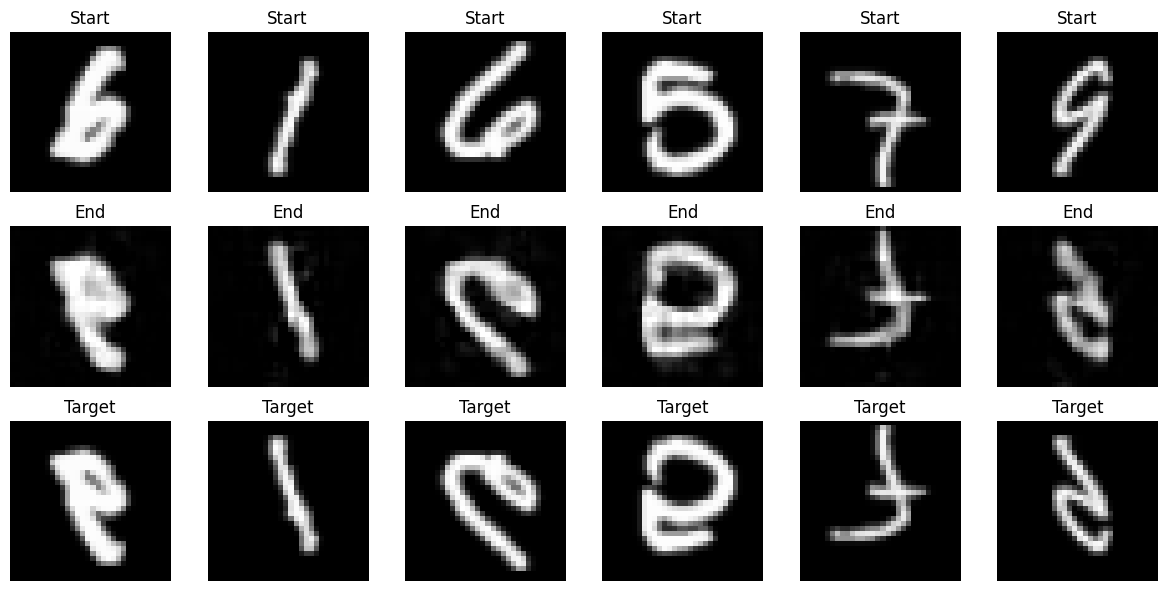

Average error between evolved samples and target: 0.06374451518058777


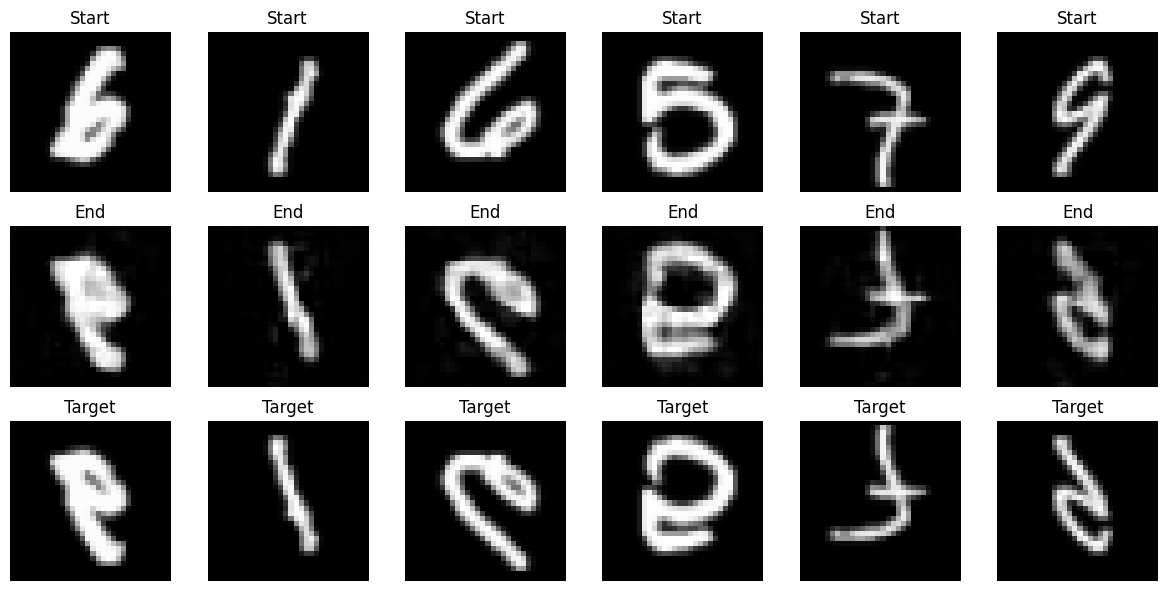

Average error between evolved samples and target: 0.06396771967411041


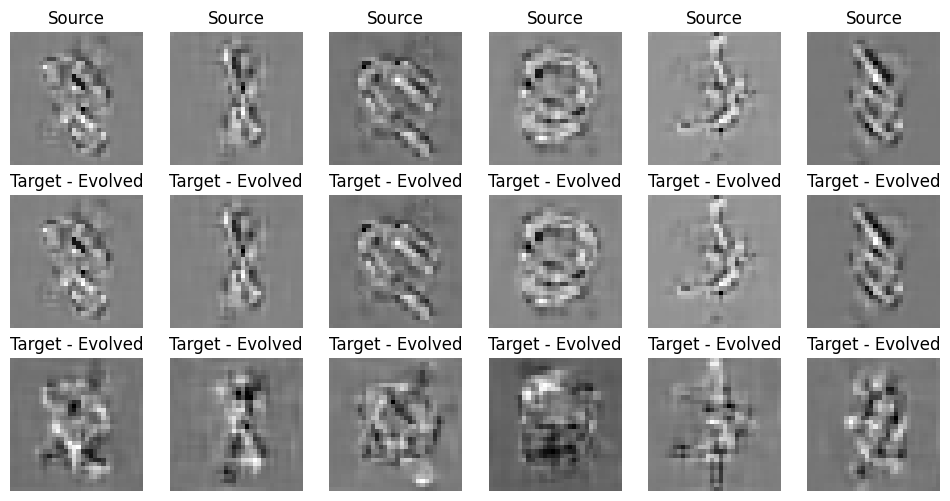

First layer weights of the forward model:
tensor([[[[ 0.0991,  0.1729, -0.1879],
          [-0.2100, -0.0391, -0.0285],
          [ 0.0495,  0.0870, -0.1130]],

         [[-0.1068, -0.1124, -0.1626],
          [ 0.2559,  0.2931,  0.1689],
          [-0.1910,  0.2249,  0.0042]]]])
First layer weights of the forward model:
tensor([[[[ 0.0989,  0.1728, -0.1879],
          [-0.2101, -0.0392, -0.0284],
          [ 0.0495,  0.0870, -0.1130]],

         [[-0.1072, -0.1123, -0.1625],
          [ 0.2553,  0.2930,  0.1690],
          [-0.1913,  0.2246,  0.0041]]]])


In [ ]:
import matplotlib.pyplot as plt
n_samples = 6
x = trainer.new_source.sample(n_samples)
y_target = x.flip(dims=[2])
x, y_target = x.to(trainer.device), y_target.to(trainer.device)
y = trainer.flow_matching.evolve(
    x,
    trainer.strategy.forward_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y = y[:, :1, :, :]
# trainer.visualizer._display_evolution(x.cpu(), y.cpu(), y_target.cpu())
# plt.show()

# Print the average error between the evolved samples and the target
error = torch.mean(torch.abs(y - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

initial_model = trainer.strategy.initial_forward_model
state_dict = torch.load('experiments/image_flip_models/initial_forward_model.pth', map_location=trainer.device)
initial_model.load_state_dict(state_dict)
n_samples = 6
y_init = trainer.flow_matching.evolve(
    x,
    initial_model,
    num_steps=25,
    sigma=0.0,
    extend=True,
)
y_init = y_init[:, :1, :, :]
# trainer.visualizer._display_evolution(x.cpu(), y_init.cpu(), y_target.cpu())
# plt.show()


error = torch.mean(torch.abs(y_init - y_target))
print(f"Average error between evolved samples and target: {error.item()}")

# plt.figure(figsize=(12, 6))
# for i in range(n_samples):
#     plt.subplot(3, n_samples, i + 1)
#     plt.imshow(y_target[i, 0].cpu() - y[i, 0].cpu(), cmap='gray')
#     plt.title('Source')
#     plt.axis('off')

#     plt.subplot(3, n_samples, n_samples + i + 1)
#     plt.imshow(y_target[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
#     plt.title('Target - Evolved')
#     plt.axis('off')

#     plt.subplot(3, n_samples, 2 * n_samples + i + 1)
#     plt.imshow(y[i, 0].cpu() - y_init[i, 0].cpu(), cmap='gray')
#     plt.title('Target - Evolved')
#     plt.axis('off')
# plt.show()

# Print weights of the first layer of the forward model
first_layer_weights = trainer.strategy.forward_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

first_layer_weights = initial_model.model.input_blocks[0][0].weight.data.cpu()
print("First layer weights of the forward model:")
print(first_layer_weights[:1])  # Print the weights of the first 5 filters

# unet_wrapper(
#   (model): UNetModelWrapper(
#     (time_embed): Sequential(
#       (0): Linear(in_features=32, out_features=128, bias=True)
#       (1): SiLU()
#       (2): Linear(in_features=128, out_features=128, bias=True)
#     )
#     (input_blocks): ModuleList(
#       (0): TimestepEmbedSequential(
#         (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#       )
#       (1): TimestepEmbedSequential(
#         (0): ResBlock(
#           (in_layers): Sequential(
#             (0): GroupNorm32(32, 32, eps=1e-05, affine=True)
#             (1): SiLU()
#             (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
#           )

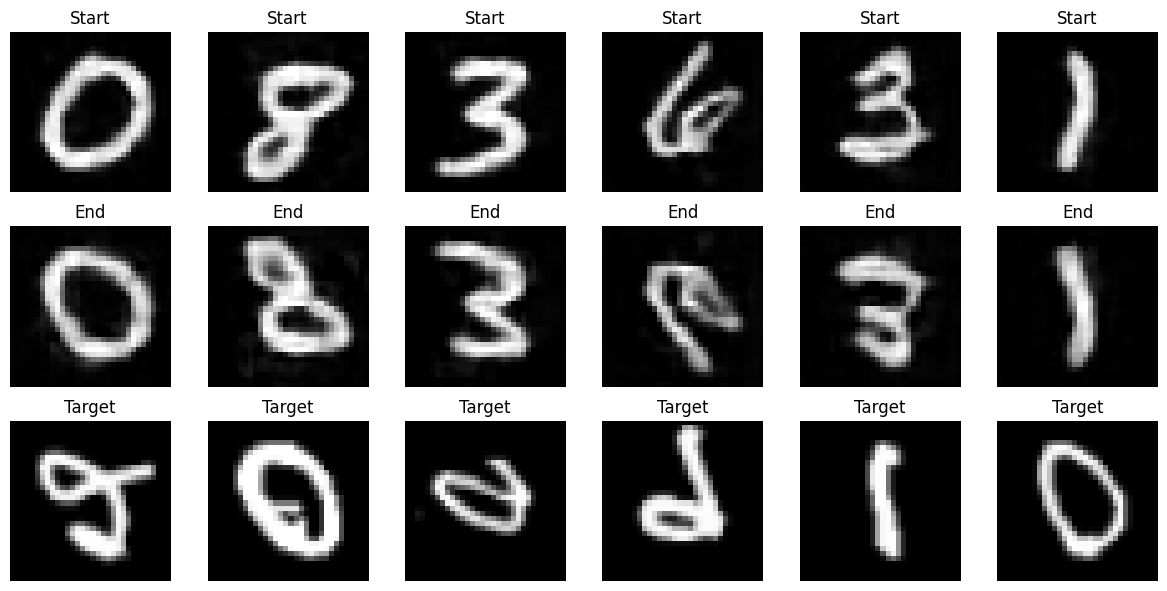

In [8]:
import matplotlib.pyplot as plt
trainer.visualizer.display(10, trainer)
plt.show()

trainer.visualizer.display(11, trainer)
plt.show()